In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('df_clustering.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17160 entries, 0 to 17159
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   time                    17160 non-null  object 
 1   cpu_user                17160 non-null  float64
 2   cpu_system              17160 non-null  float64
 3   memoria_used            17160 non-null  float64
 4   disco_used_frac         17160 non-null  float64
 5   red_bytes_s             17160 non-null  float64
 6   tasa_llamadas_pedidos   17160 non-null  float64
 7   tasa_llamadas_catalogo  17160 non-null  float64
 8   perfil                  17160 non-null  object 
dtypes: float64(7), object(2)
memory usage: 1.2+ MB


In [4]:
df.head()

,time,cpu_user,cpu_system,memoria_used,disco_used_frac,red_bytes_s,tasa_llamadas_pedidos,tasa_llamadas_catalogo,perfil
0,2026-10-06 00:20:00+00:00,0.197000,0.038000,0.218574,0.148526,25491.115395,24.299558,47.499136,Operación normal
1,2026-10-06 00:20:10+00:00,0.210059,0.040434,0.218544,0.148527,24661.480395,33.301280,62.002382,Operación normal
2,2026-10-06 00:20:20+00:00,0.173695,0.037149,0.217593,0.148527,17657.556489,18.800486,39.001008,Operación normal
3,2026-10-06 00:20:30+00:00,0.192385,0.038076,0.218207,0.148527,23276.729134,25.300219,48.500420,Operación normal
4,2026-10-06 00:20:40+00:00,0.170854,0.033166,0.218044,0.148528,23009.757567,30.299115,62.498175,Operación normal


# División y normalización ✂️

Fecha de corte: 2026-10-07 09:42:00+00:00
Tamaño de entrenamiento: 11893 muestras (2026-10-06 00:39:50+00:00 a 2026-10-07 09:41:50+00:00)
Tamaño de prueba: 5148 muestras (2026-10-07 09:42:00+00:00 a 2026-10-07 23:59:50+00:00)

Distribución de clases en entrenamiento (proporción):
perfil
Operación normal         0.9332
Disco en llenado         0.0399
Saturación de CPU        0.0128
Caída de servicio        0.0080
Saturación de memoria    0.0061
Name: proportion, dtype: float64

Distribución de clases en prueba (proporción):
perfil
Operación normal         0.8850
Disco en llenado         0.0699
Saturación de CPU        0.0241
Saturación de memoria    0.0177
Caída de servicio        0.0033
Name: proportion, dtype: float64


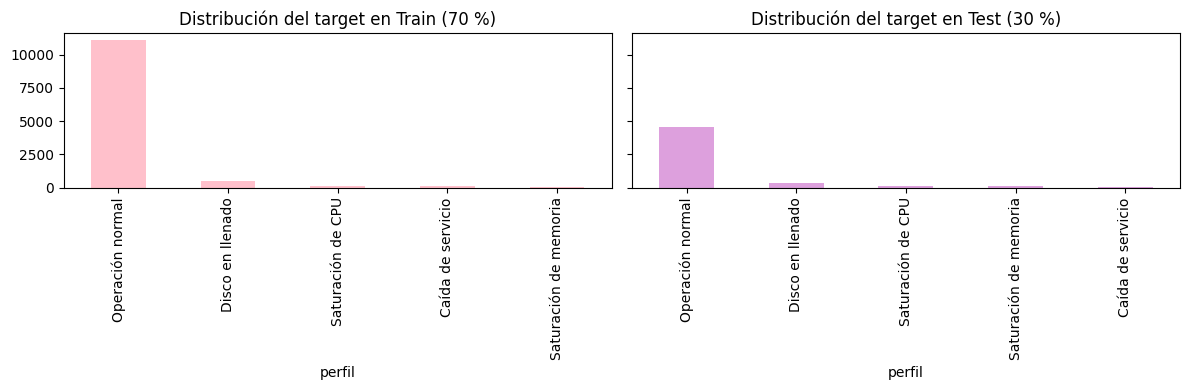

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. La fecha como índice (se usa para normalizar y dividir, NO como variable)
if 'time' in df.columns:
    df['time'] = pd.to_datetime(df['time'], utc=True)
    df = df.set_index('time')
df = df.sort_index()

variables = ['cpu_user', 'cpu_system', 'memoria_used', 'disco_used_frac',
             'red_bytes_s', 'tasa_llamadas_pedidos', 'tasa_llamadas_catalogo']
tasas = ['red_bytes_s', 'tasa_llamadas_pedidos', 'tasa_llamadas_catalogo']

# 2. División 70/30 POR TIEMPO (sin mezclar): el 70 % más antiguo entrena, el 30 % más reciente prueba
corte = df.index[int(len(df) * 0.70)]
print('Fecha de corte:', corte)

# 3. Normalización sobre el 100 %: cada punto se compara solo con SU pasado (la última hora),
#    así que no se filtra información del futuro. El piso se calcula SOLO con datos de entrenamiento
X_log = df[variables].copy()
X_log[tasas] = np.log1p(X_log[tasas])

previa = X_log.shift(1)
mediana = previa.rolling('60min', min_periods=60).median()
mad = (previa - mediana).abs().rolling('60min', min_periods=60).median()

calentamiento = X_log.loc[:'2026-10-06T12:08:20Z']          # periodo sin fallos, dentro del 70 %
piso = (0.1 * calentamiento.std()).clip(lower=1e-6)

Z = 0.6745 * (X_log - mediana) / mad.clip(lower=piso, axis=1)
Z = Z.clip(-20, 20).dropna()                                # descarta los primeros 20 min sin historia

# 4. Variables predictoras (X) y objetivo (y), alineadas por fecha
X = Z[variables]
y = df.loc[X.index, 'perfil']

X_train, y_train = X[X.index < corte], y[y.index < corte]
X_test,  y_test  = X[X.index >= corte], y[y.index >= corte]

# 5. Tamaños y proporciones (el 30 % de prueba NO se balancea: conserva la proporción real)
print(f"Tamaño de entrenamiento: {X_train.shape[0]} muestras ({X_train.index.min()} a {X_train.index.max()})")
print(f"Tamaño de prueba: {X_test.shape[0]} muestras ({X_test.index.min()} a {X_test.index.max()})\n")
print("Distribución de clases en entrenamiento (proporción):")
print(y_train.value_counts(normalize=True).round(4))
print("\nDistribución de clases en prueba (proporción):")
print(y_test.value_counts(normalize=True).round(4))

# 6. Gráficas de la distribución en cada conjunto
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
y_train.value_counts().plot(kind='bar', color='pink', ax=ejes[0], title='Distribución del target en Train (70 %)')
y_test.value_counts().plot(kind='bar', color='plum', ax=ejes[1], title='Distribución del target en Test (30 %)')
plt.tight_layout()
plt.show()

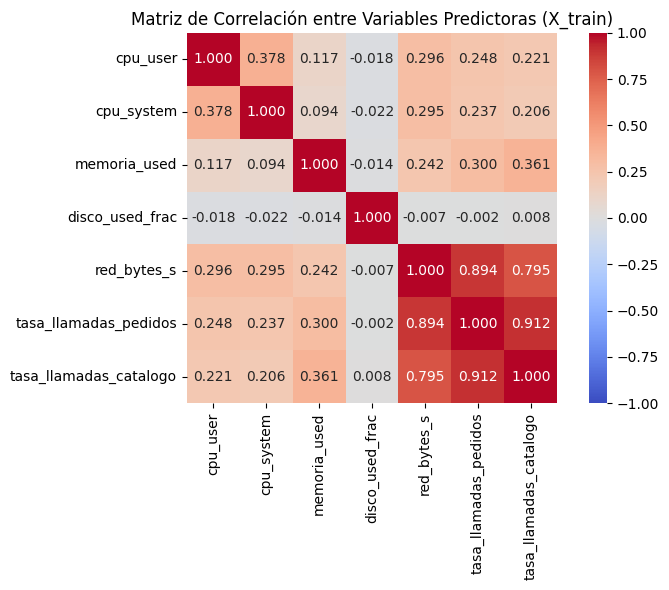

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calcular la matriz de correlación de Pearson en el conjunto de entrenamiento
matriz_corr = X_train.corr()

# Configurar y graficar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz de Correlación entre Variables Predictoras (X_train)')
plt.tight_layout()
plt.show()

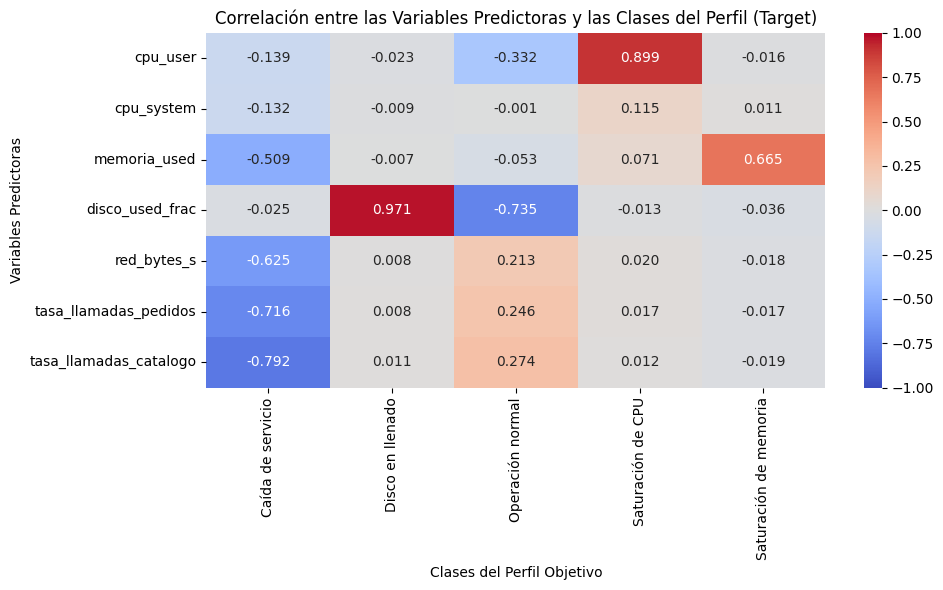

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Crear un DataFrame temporal uniendo las variables predictoras con la variable objetivo codificada en one-hot
y_train_encoded = pd.get_dummies(y_train, prefix='', prefix_sep='')
df_corr_target = pd.concat([X_train, y_train_encoded], axis=1)

# 2. Calcular la matriz de correlación completa y filtrar la relación entre predictoras y clases objetivo
matriz_completa = df_corr_target.corr()
correlacion_objetivo = matriz_completa.loc[X_train.columns, y_train_encoded.columns]

# 3. Graficar el mapa de calor de correlación con la variable objetivo
plt.figure(figsize=(10, 6))
sns.heatmap(correlacion_objetivo, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=False)
plt.title('Correlación entre las Variables Predictoras y las Clases del Perfil (Target)')
plt.ylabel('Variables Predictoras')
plt.xlabel('Clases del Perfil Objetivo')
plt.tight_layout()
plt.show()

**Nota sobre la segunda matriz.** La correlación entre las variables y los perfiles sale alta por construcción: los perfiles los creó KMeans a partir de estas mismas variables. Sirve para describir qué variable define cada perfil, no como evidencia de que el modelo predice bien.

# Modelos predictivos 🤖

Los cuatro modelos usan las mismas `X_train`, `y_train`, `X_test` y `y_test` de la celda anterior: las 7 variables normalizadas, con división 70/30 por tiempo.

- **Sin corrección del desbalance** en ninguno de los cuatro, para compararlos en igualdad de condiciones (la literatura y la comparación previa mostraron que no mejora el resultado).
- **SVM, KNN y red neuronal** dependen de distancias o gradientes, por eso llevan un `StandardScaler` dentro de un `Pipeline`: se ajusta solo con entrenamiento y se aplica igual a prueba.
- **`random_state=42`** en todos los que tienen azar, para que el resultado sea repetible.

In [8]:
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay

# Función común para las métricas: así los cuatro modelos se evalúan exactamente igual
resultados = {}

def evaluar(nombre, modelo):
    pred = modelo.predict(X_test)
    resultados[nombre] = {
        'F1 macro': f1_score(y_test, pred, average='macro'),
        'F1 ponderado': f1_score(y_test, pred, average='weighted'),
    }
    print(f'===== {nombre} =====')
    print(classification_report(y_test, pred, digits=3, zero_division=0))
    print(f"F1 macro: {resultados[nombre]['F1 macro']:.3f}")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45, cmap='Purples')
    plt.title(f'Matriz de confusión: {nombre}')
    plt.show()

## Árbol de decisión 🌳

In [9]:
from sklearn.tree import DecisionTreeClassifier, export_text

arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol.fit(X_train, y_train)

# Las reglas que aprendió el árbol (útiles para explicar cada perfil)
print(export_text(arbol, feature_names=list(X_train.columns), decimals=1))

|--- disco_used_frac <= 10.5
|   |--- cpu_user <= 8.2
|   |   |--- tasa_llamadas_catalogo <= -8.2
|   |   |   |--- class: Caída de servicio
|   |   |--- tasa_llamadas_catalogo >  -8.2
|   |   |   |--- memoria_used <= 13.7
|   |   |   |   |--- class: Operación normal
|   |   |   |--- memoria_used >  13.7
|   |   |   |   |--- class: Saturación de memoria
|   |--- cpu_user >  8.2
|   |   |--- class: Saturación de CPU
|--- disco_used_frac >  10.5
|   |--- class: Disco en llenado



===== Árbol de decisión =====
                       precision    recall  f1-score   support

    Caída de servicio      1.000     1.000     1.000        17
     Disco en llenado      1.000     1.000     1.000       360
     Operación normal      1.000     1.000     1.000      4556
    Saturación de CPU      0.992     1.000     0.996       124
Saturación de memoria      1.000     1.000     1.000        91

             accuracy                          1.000      5148
            macro avg      0.998     1.000     0.999      5148
         weighted avg      1.000     1.000     1.000      5148

F1 macro: 0.999


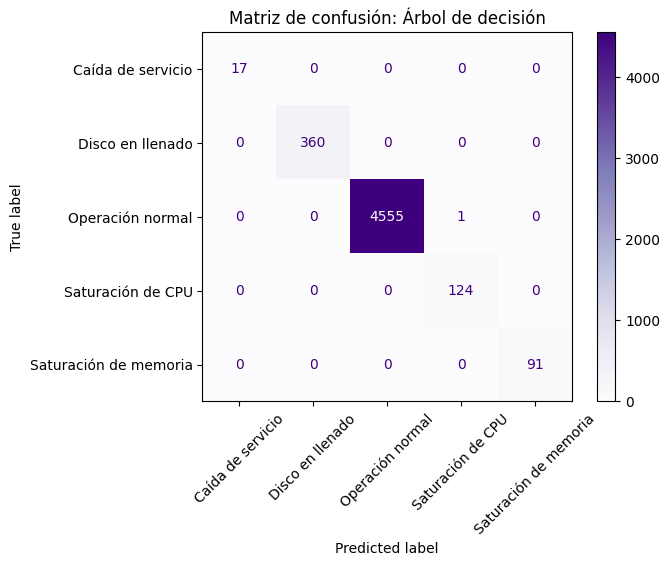

In [10]:
evaluar('Árbol de decisión', arbol)

## Máquina de soporte vectorial (SVM) 📐

**Se usa kernel lineal.** Con el kernel RBF (el que trae sklearn por defecto), la SVM no detectó ninguna caída en la prueba (recall 0; F1 macro 0,796), aunque se probó con `C` = 1, 10 y 100 y con `class_weight='balanced'`. La causa: en entrenamiento las caídas son casi todas de `pedidos`, donde también baja el tráfico de red, pero la caída de prueba es de `catalogo`, donde el tráfico de red sube. El kernel RBF decide por cercanía a los ejemplos vistos y esa caída queda lejos de todos. El kernel lineal aprende la dirección general ("tasa de llamadas muy por debajo de lo normal") y sí generaliza.

In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0, random_state=42))
svm.fit(X_train, y_train)
print(svm)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(kernel='linear', random_state=42))])


===== SVM =====
                       precision    recall  f1-score   support

    Caída de servicio      1.000     1.000     1.000        17
     Disco en llenado      1.000     1.000     1.000       360
     Operación normal      1.000     1.000     1.000      4556
    Saturación de CPU      1.000     0.984     0.992       124
Saturación de memoria      1.000     1.000     1.000        91

             accuracy                          1.000      5148
            macro avg      1.000     0.997     0.998      5148
         weighted avg      1.000     1.000     1.000      5148

F1 macro: 0.998


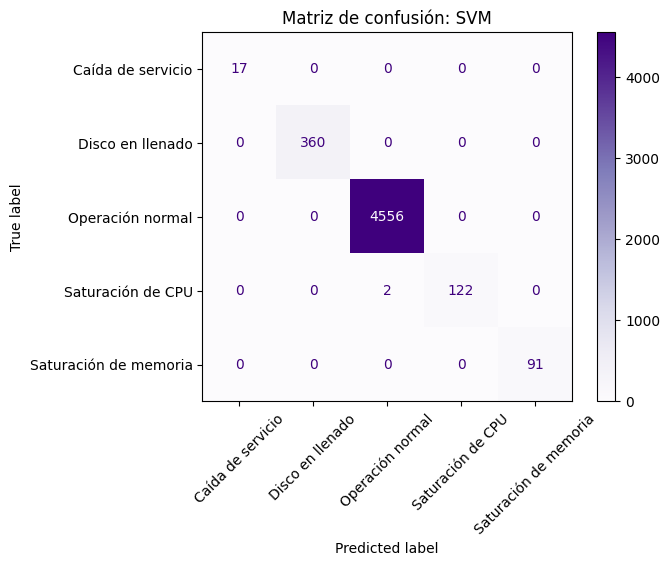

In [12]:
evaluar('SVM', svm)

## K vecinos más cercanos (KNN) 📍

In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)
print(knn)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('kneighborsclassifier', KNeighborsClassifier())])


===== KNN =====
                       precision    recall  f1-score   support

    Caída de servicio      1.000     1.000     1.000        17
     Disco en llenado      1.000     1.000     1.000       360
     Operación normal      1.000     1.000     1.000      4556
    Saturación de CPU      0.992     0.984     0.988       124
Saturación de memoria      1.000     0.989     0.994        91

             accuracy                          0.999      5148
            macro avg      0.998     0.995     0.996      5148
         weighted avg      0.999     0.999     0.999      5148

F1 macro: 0.996


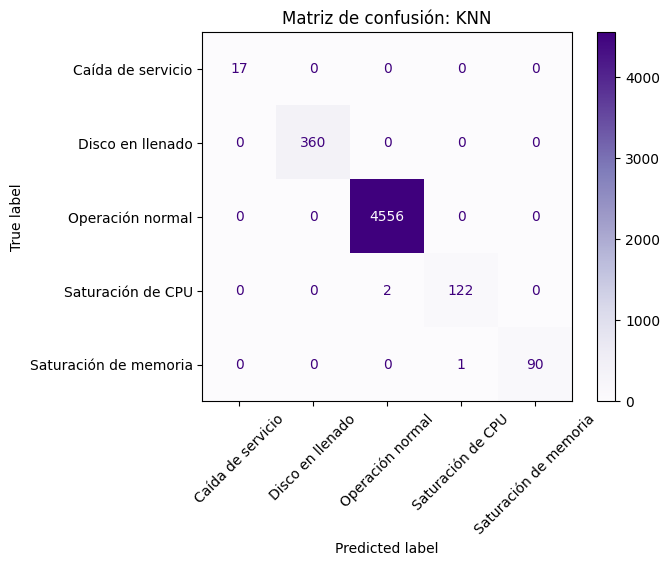

In [14]:
evaluar('KNN', knn)

## Red neuronal (perceptrón multicapa) 🧠

In [15]:
from sklearn.neural_network import MLPClassifier

red = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', max_iter=500,
                  early_stopping=False, random_state=42)
)
red.fit(X_train, y_train)
print(red)
print('Iteraciones hasta converger:', red[-1].n_iter_)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('mlpclassifier',
                 MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500,
                               random_state=42))])
Iteraciones hasta converger: 32


===== Red neuronal =====
                       precision    recall  f1-score   support

    Caída de servicio      1.000     0.882     0.938        17
     Disco en llenado      1.000     1.000     1.000       360
     Operación normal      1.000     1.000     1.000      4556
    Saturación de CPU      0.992     1.000     0.996       124
Saturación de memoria      1.000     1.000     1.000        91

             accuracy                          0.999      5148
            macro avg      0.998     0.976     0.987      5148
         weighted avg      0.999     0.999     0.999      5148

F1 macro: 0.987


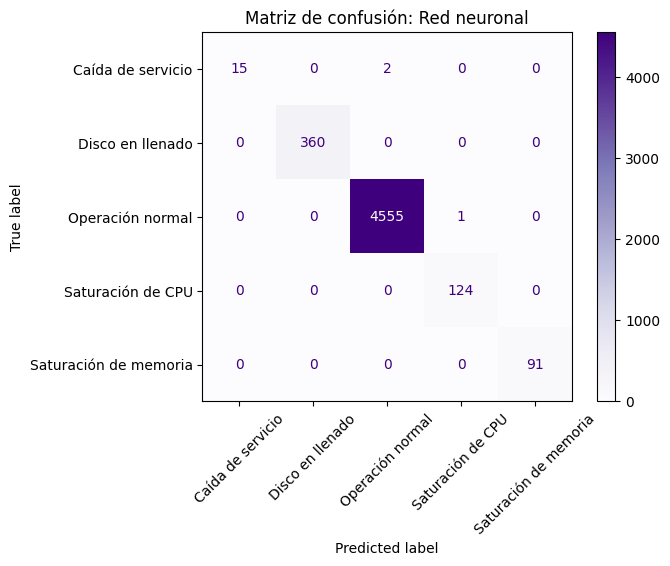

In [16]:
evaluar('Red neuronal', red)

# Comparación de modelos 📊

,F1 macro,F1 ponderado
Árbol de decisión,0.999,1.000
SVM,0.998,1.000
KNN,0.996,0.999
Red neuronal,0.987,0.999


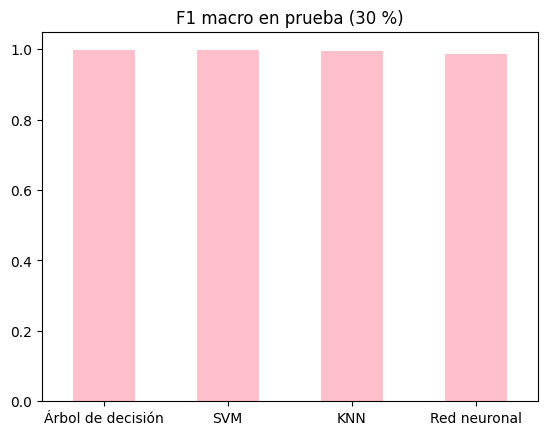

In [17]:
comparacion = pd.DataFrame(resultados).T.sort_values('F1 macro', ascending=False)
display(comparacion.round(3))

comparacion['F1 macro'].plot(kind='bar', color='pink', title='F1 macro en prueba (30 %)', ylim=(0, 1.05))
plt.xticks(rotation=0)
plt.show()

In [18]:
# ===== Celda 1: las dos pruebas para los cuatro modelos =====
from sklearn.base import clone

modelos = {'Árbol de decisión': arbol, 'SVM': svm, 'KNN': knn, 'Red neuronal': red}
NORMAL = 'Operación normal'

# Eventos de fallo: bloques seguidos con el mismo perfil, de al menos 3 filas (30 s)
cambio = (y != y.shift()) | (y.index.to_series().diff() > pd.Timedelta('10s'))
bloque = cambio.cumsum()
eventos = bloque[y != NORMAL]
tamanos = eventos.value_counts()
eventos = eventos[eventos.isin(tamanos[tamanos >= 3].index)]
print('Eventos de fallo:', eventos.nunique(), '|', y[eventos.index].groupby(eventos).first().value_counts().to_dict())

# --- Prueba 1: dejar un evento fuera ---
filas = []
for ev, idx in eventos.groupby(eventos).groups.items():
    ini, fin = idx.min(), idx.max()
    fuera = (X.index >= ini - pd.Timedelta('10min')) & (X.index <= fin + pd.Timedelta('10min'))
    clase = y[idx[0]]
    for nombre, modelo in modelos.items():
        m = clone(modelo).fit(X[~fuera], y[~fuera])
        filas.append({'evento': ev, 'clase': clase, 'modelo': nombre,
                      'recall': (m.predict(X.loc[idx]) == clase).mean()})
dejar_uno = pd.DataFrame(filas)

print('\nPrueba 1 · Recall medio por clase cuando el evento NO se vio en entrenamiento:')
display(dejar_uno.pivot_table(index='clase', columns='modelo', values='recall', aggfunc='mean').round(2))

# --- Prueba 2: fallos más débiles ---
factores = [1.0, 0.75, 0.5, 0.3]
fallo = y_test != NORMAL
filas = []
for nombre, modelo in modelos.items():
    for a in factores:
        X_debil = X_test.copy()
        X_debil.loc[fallo] = X_debil.loc[fallo] * a
        pred = pd.Series(modelo.predict(X_debil), index=X_test.index)
        for clase in y_test[fallo].unique():
            filas.append({'modelo': nombre, 'factor': a, 'clase': clase,
                          'recall': (pred[y_test == clase] == clase).mean()})
sensibilidad = pd.DataFrame(filas)

print('\nPrueba 2 · Recall por clase según la intensidad del fallo (1 = intensidad real):')
display(sensibilidad.pivot_table(index=['clase', 'modelo'], columns='factor', values='recall')
        .round(2)[sorted(factores, reverse=True)])

Eventos de fallo: 21 | {'Disco en llenado': 10, 'Saturación de CPU': 5, 'Caída de servicio': 4, 'Saturación de memoria': 2}

Prueba 1 · Recall medio por clase cuando el evento NO se vio en entrenamiento:


modelo,KNN,Red neuronal,SVM,Árbol de decisión
clase,,,,
Caída de servicio,0.99,0.64,0.99,0.99
Disco en llenado,1.00,1.00,1.00,1.00
Saturación de CPU,1.00,0.90,1.00,1.00
Saturación de memoria,0.99,0.99,1.00,1.00



Prueba 2 · Recall por clase según la intensidad del fallo (1 = intensidad real):


factor                                   1.00  0.75  0.50  0.30
clase                 modelo                                   
Caída de servicio     KNN                1.00  0.94  0.00   0.0
                      Red neuronal       0.88  0.06  0.00   0.0
                      SVM                1.00  1.00  0.00   0.0
                      Árbol de decisión  1.00  1.00  1.00   0.0
Disco en llenado      KNN                1.00  1.00  0.00   0.0
                      Red neuronal       1.00  1.00  0.98   0.0
                      SVM                1.00  1.00  0.00   0.0
                      Árbol de decisión  1.00  1.00  0.00   0.0
Saturación de CPU     KNN                0.98  0.97  0.00   0.0
                      Red neuronal       1.00  0.98  0.79   0.0
                      SVM                0.98  0.32  0.01   0.0
                      Árbol de decisión  1.00  0.98  0.85   0.0
Saturación de memoria KNN                0.99  0.99  0.00   0.0
                      Red neuronal       1.00  1.00  0.47   0.0
                      SVM                1.00  1.00  0.00   0.0
                      Árbol de decisión  1.00  1.00  0.00   0.0

In [19]:
# ===== Celda 2: tabla comparativa =====
from sklearn.metrics import f1_score, recall_score

clases_fallo = sorted(y_test[y_test != NORMAL].unique())
filas = []
for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)
    p1 = dejar_uno[dejar_uno['modelo'] == nombre]
    p2 = sensibilidad[sensibilidad['modelo'] == nombre].groupby('factor')['recall'].mean()
    filas.append({
        'Modelo': nombre,
        'F1 macro (prueba 30 %)': f1_score(y_test, pred, average='macro'),
        'Recall mínimo por clase (prueba 30 %)': recall_score(y_test, pred, labels=clases_fallo, average=None).min(),
        'Recall medio, evento no visto': p1['recall'].mean(),
        'Peor clase, evento no visto': p1.groupby('clase')['recall'].mean().min(),
        'Eventos perdidos (de %d)' % p1['evento'].nunique(): int((p1['recall'] < 0.5).sum()),
        'Recall fallos al 75 %': p2.get(0.75),
        'Recall fallos al 50 %': p2.get(0.5),
    })

comparativa = pd.DataFrame(filas).set_index('Modelo').round(3)
comparativa = comparativa.sort_values(['Eventos perdidos (de %d)' % eventos.nunique(), 'F1 macro (prueba 30 %)'],
                                      ascending=[True, False])
display(comparativa)

,F1 macro (prueba 30 %),Recall mínimo por clase (prueba 30 %),"Recall medio, evento no visto","Peor clase, evento no visto",Eventos perdidos (de 21),Recall fallos al 75 %,Recall fallos al 50 %
Modelo,,,,,,,
Árbol de decisión,0.999,1.000,0.998,0.990,0,0.994,0.464
SVM,0.998,0.984,0.998,0.990,0,0.831,0.002
KNN,0.996,0.984,0.997,0.988,0,0.974,0.000
Red neuronal,0.987,0.882,0.907,0.644,1,0.761,0.561


In [20]:
from sklearn.metrics import classification_report
import pandas as pd

# Obtener las categorías únicas de interés
categorias = sorted(y_test.unique())
desempeno_filas = []

for nombre, modelo in modelos.items():
    pred = modelo.predict(X_test)
    # Usamos output_dict=True para extraer las métricas de cada clase
    reporte = classification_report(y_test, pred, output_dict=True, zero_division=0)

    fila = {'Modelo': nombre}
    for cat in categorias:
        # Guardamos el F1-score para cada categoría
        fila[cat] = reporte[cat]['f1-score']
    desempeno_filas.append(fila)

# Crear el DataFrame y mostrarlo de forma ordenada
df_desempeno = pd.DataFrame(desempeno_filas).set_index('Modelo')
print("Desempeño por categoría (F1-Score en test):")
display(df_desempeno.round(4))

Desempeño por categoría (F1-Score en test):


,Caída de servicio,Disco en llenado,Operación normal,Saturación de CPU,Saturación de memoria
Modelo,,,,,
Árbol de decisión,1.0000,1.0,0.9999,0.9960,1.0000
SVM,1.0000,1.0,0.9998,0.9919,1.0000
KNN,1.0000,1.0,0.9998,0.9879,0.9945
Red neuronal,0.9375,1.0,0.9997,0.9960,1.0000


# Validación cruzada y comparación estadística 📏

**Por qué bloques de tiempo y no `KFold(shuffle=True)`.** Con filas cada 10 s, dos filas seguidas son casi idénticas. Si se mezclan, una queda en entrenamiento y la vecina en validación, y el modelo "acierta" porque ya vio casi el mismo punto. Con `KFold(shuffle=False)` cada pliegue es un bloque continuo de tiempo.

- Se usa **solo el 70 % de entrenamiento**: el 30 % de prueba queda intacto para la evaluación final.
- **Limitación de la prueba estadística:** los pliegues comparten datos de entrenamiento, así que sus puntajes no son independientes, que es un supuesto del ANOVA. Los valores p se reportan como orientativos, no como prueba concluyente.
- **Por qué los pliegues varían tanto:** cuando un bloque contiene el único evento de un tipo de fallo (por ejemplo, la única memoria del entrenamiento), el modelo de ese pliegue nunca vio esa clase y no puede detectarla.

In [21]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import make_scorer, f1_score
import scipy.stats as stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Bloques continuos de tiempo, sin mezclar, solo sobre el 70 % de entrenamiento
cv_tiempo = KFold(n_splits=5, shuffle=False)
f1_macro = make_scorer(f1_score, average='macro', zero_division=0)

resultados_cv = {}
print('F1 macro por bloques de tiempo (validación cruzada sobre entrenamiento):')
for nombre, modelo in modelos.items():
    scores = cross_val_score(modelo, X_train, y_train, cv=cv_tiempo, scoring=f1_macro)
    resultados_cv[nombre] = scores
    print(f'{nombre:18} media = {scores.mean():.4f}, std = {scores.std():.4f} | por bloque: {np.round(scores, 3)}')

# ANOVA de una vía (orientativo: los pliegues no son independientes)
f_stat, p_val = stats.f_oneway(*resultados_cv.values())
print(f'\nANOVA de una vía: F = {f_stat:.4f}, p = {p_val:.4f}')
print('Diferencia significativa (p < 0,05)' if p_val < 0.05 else 'Sin diferencia significativa entre modelos (p >= 0,05)')

valores = np.concatenate(list(resultados_cv.values()))
grupos = np.repeat(list(resultados_cv.keys()), [len(v) for v in resultados_cv.values()])
print('\nPrueba post-hoc de Tukey HSD:')
print(pairwise_tukeyhsd(endog=valores, groups=grupos, alpha=0.05))

F1 macro por bloques de tiempo (validación cruzada sobre entrenamiento):


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 380, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 90, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/

Árbol de decisión  media = nan, std = nan | por bloque: [nan nan nan nan nan]


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 380, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 90, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/

SVM                media = nan, std = nan | por bloque: [nan nan nan nan nan]
KNN                media = nan, std = nan | por bloque: [nan nan nan nan nan]


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 140, in __call__
    score = scorer._score(
        cached_call, estimator, *args, **routed_params.get(name).score
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 380, in _score
    y_pred = method_caller(
        estimator,
    ...<2 lines>...
        pos_label=pos_label,
    )
  File "/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_scorer.py", line 90, in _cached_call
    result, _ = _get_response_values(
                ~~~~~~~~~~~~~~~~~~~~^
        estimator, *args, response_method=response_method, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/

Red neuronal       media = nan, std = nan | por bloque: [nan nan nan nan nan]

ANOVA de una vía: F = nan, p = nan
Sin diferencia significativa entre modelos (p >= 0,05)

Prueba post-hoc de Tukey HSD:
      Multiple Comparison of Means - Tukey HSD, FWER=0.05       
   group1          group2      meandiff p-adj lower upper reject
----------------------------------------------------------------
         KNN      Red neuronal      nan   nan   nan   nan  False
         KNN               SVM      nan   nan   nan   nan  False
         KNN Árbol de decisión      nan   nan   nan   nan  False
Red neuronal               SVM      nan   nan   nan   nan  False
Red neuronal Árbol de decisión      nan   nan   nan   nan  False
         SVM Árbol de decisión      nan   nan   nan   nan  False
----------------------------------------------------------------


# Hiperparametrización del árbol 🔧

Misma validación por bloques de tiempo. La optimización bayesiana lleva semilla (`TPESampler(seed=42)`) para que dé el mismo resultado en cada ejecución.

**Criterio de selección:** se elige por el F1 macro de validación cruzada, no por el de prueba. Si dos modelos empatan, se queda el más simple (menos hojas), porque la complejidad extra no aporta y aumenta el riesgo de sobreajuste.

In [24]:
!pip install -q optuna

import optuna
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier
import warnings

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 1. Grid search
param_grid = {
    'max_depth': [3, 4, 5, 8, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy'],
}
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid,
                           scoring='f1_macro', cv=cv_tiempo, n_jobs=-1)
grid_search.fit(X_train, y_train)
best_grid_model = grid_search.best_estimator_
print('Mejores parámetros Grid Search:', grid_search.best_params_)
print(f'F1 macro CV (Grid): {grid_search.best_score_:.4f}')

# 2. Optimización bayesiana (con semilla)
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 2, 15),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'criterion': trial.suggest_categorical('criterion', ['gini', 'entropy']),
    }
    clf = DecisionTreeClassifier(**params, random_state=42)
    return cross_val_score(clf, X_train, y_train, cv=cv_tiempo, scoring='f1_macro').mean()

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30)
best_bayes_model = DecisionTreeClassifier(**study.best_params, random_state=42).fit(X_train, y_train)
print('\nMejores parámetros Bayesiano:', study.best_params)
print(f'F1 macro CV (Bayesiano): {study.best_value:.4f}')

# 3. Elegir por validación cruzada; si empatan, el más simple
# Nota: Como resultados_cv contenía NaNs por el error anterior, recalculamos de forma segura
arbol_score = cross_val_score(arbol, X_train, y_train, cv=cv_tiempo, scoring='f1_macro').mean()

candidatos = {
    'Árbol original': (arbol, arbol_score),
    'Árbol Grid Search': (best_grid_model, grid_search.best_score_),
    'Árbol Opt. Bayesiana': (best_bayes_model, study.best_value),
}
tabla_arboles = pd.DataFrame({
    n: {'F1 macro CV': s, 'Hojas': m.get_n_leaves(), 'Profundidad': m.get_depth(),
        'F1 macro prueba (solo informativo)': f1_score(y_test, m.predict(X_test), average='macro')}
    for n, (m, s) in candidatos.items()}).T
display(tabla_arboles.round(4))

mejor_cv = tabla_arboles['F1 macro CV'].max()
empatados = tabla_arboles[tabla_arboles['F1 macro CV'] >= mejor_cv - 0.001]
nombre_final = empatados.sort_values('Hojas').index[0]
modelo_final = candidatos[nombre_final][0]
print(f'\nModelo elegido: {nombre_final}')

Mejores parámetros Grid Search: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2}
F1 macro CV (Grid): 0.8975

Mejores parámetros Bayesiano: {'max_depth': 10, 'min_samples_split': 4, 'min_samples_leaf': 3, 'criterion': 'entropy'}
F1 macro CV (Bayesiano): 0.8975


,F1 macro CV,Hojas,Profundidad,F1 macro prueba (solo informativo)
Árbol original,0.8673,5.0,4.0,0.9992
Árbol Grid Search,0.8975,5.0,4.0,0.9992
Árbol Opt. Bayesiana,0.8975,5.0,4.0,0.9992



Modelo elegido: Árbol Grid Search


# Sobreajuste y robustez 🧪

- **Sobreajuste:** se compara el F1 macro en entrenamiento y en prueba, con los datos reales. Una diferencia grande indica que el modelo memorizó el entrenamiento.
- **Robustez:** recall de las clases de fallo en prueba cuando los fallos se reducen al 50 % de su intensidad (simulación).

In [25]:
arboles = {'Árbol original': arbol, 'Árbol Grid Search': best_grid_model, 'Árbol Opt. Bayesiana': best_bayes_model}
fallo_test = y_test != NORMAL
clases_fallo_test = sorted(y_test[fallo_test].unique())

X_test_50 = X_test.copy()
X_test_50.loc[fallo_test] = X_test_50.loc[fallo_test] * 0.5

filas = []
for nombre, modelo in arboles.items():
    f1_train = f1_score(y_train, modelo.predict(X_train), average='macro')
    f1_test = f1_score(y_test, modelo.predict(X_test), average='macro')
    pred_50 = modelo.predict(X_test_50)
    filas.append({
        'Modelo': nombre,
        'F1 macro entrenamiento': f1_train,
        'F1 macro prueba': f1_test,
        'Diferencia (sobreajuste)': f1_train - f1_test,
        'Recall fallos al 50 % (prueba)': recall_score(y_test[fallo_test], pred_50[fallo_test],
                                                        labels=clases_fallo_test, average='macro', zero_division=0),
    })
display(pd.DataFrame(filas).set_index('Modelo').round(4))

,F1 macro entrenamiento,F1 macro prueba,Diferencia (sobreajuste),Recall fallos al 50 % (prueba)
Modelo,,,,
Árbol original,1.0,0.9992,0.0008,0.4637
Árbol Grid Search,1.0,0.9992,0.0008,0.4637
Árbol Opt. Bayesiana,1.0,0.9992,0.0008,0.4637


In [26]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

pred_final = modelo_final.predict(X_test)
exactitud = accuracy_score(y_test, pred_final)
print(f'Modelo final: {nombre_final}')
print(f'Exactitud en prueba: {exactitud * 100:.2f} %  (tasa de error: {(1 - exactitud) * 100:.2f} %)')
print(f'Exactitud balanceada: {balanced_accuracy_score(y_test, pred_final) * 100:.2f} %')
print(f'F1 macro: {f1_score(y_test, pred_final, average="macro"):.4f}')
print('\nOjo: con ~88 % de filas normales, un modelo que dijera siempre "normal" tendría '
      f'{(y_test == NORMAL).mean() * 100:.1f} % de exactitud. Por eso se reportan también la exactitud balanceada y el F1 macro.')

Modelo final: Árbol Grid Search
Exactitud en prueba: 99.98 %  (tasa de error: 0.02 %)
Exactitud balanceada: 100.00 %
F1 macro: 0.9992

Ojo: con ~88 % de filas normales, un modelo que dijera siempre "normal" tendría 88.5 % de exactitud. Por eso se reportan también la exactitud balanceada y el F1 macro.


# Guardar el modelo 💾



In [27]:
import pickle, sklearn

paquete = {
    'modelo': modelo_final,
    'nombre_modelo': nombre_final,
    'variables': variables,
    'tasas_log1p': tasas,
    'ventana': '60min',
    'min_periods': 60,
    'recorte': 20,
    'piso_regla': '0.1 * desviacion estandar del periodo inicial sin fallos de cada nodo',
    'piso_nodo_entrenamiento': piso.to_dict(),
    'clases': list(modelo_final.classes_),
    'fecha_corte_entrenamiento': str(corte),
    'version_sklearn': sklearn.__version__,
}
with open('modeloestado.pkl', 'wb') as archivo:
    pickle.dump(paquete, archivo)
print('Guardado modeloestado.pkl con:', list(paquete.keys()))

Guardado modeloestado.pkl con: ['modelo', 'nombre_modelo', 'variables', 'tasas_log1p', 'ventana', 'min_periods', 'recorte', 'piso_regla', 'piso_nodo_entrenamiento', 'clases', 'fecha_corte_entrenamiento', 'version_sklearn']
